# CommerceGuard · Episode 1
## Will this order arrive on time?
Predict, **at checkout**, whether the delivery date promised to the customer will be broken,
and find a better date to promise. Data: Olist Brazilian E-commerce (public, ~100k real orders).

## Phase 0 · Problem definition

In [1]:
PROBLEM = {
    "unit": "one order",
    "prediction_time": "order placement (checkout)",
    "target": "is_late = delivered after the promised date",
    "task": "binary classification + promise-date regression",
    "primary_metric": "PR-AUC (average precision)",
    "rules": ["only checkout-time features", "chronological split", "test set used once"],
}
for k, v in PROBLEM.items():
    print(f"{k:16s} {v}")

unit             one order
prediction_time  order placement (checkout)
target           is_late = delivered after the promised date
task             binary classification + promise-date regression
primary_metric   PR-AUC (average precision)
rules            ['only checkout-time features', 'chronological split', 'test set used once']


## Phase 1 · Data understanding

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 140); sns.set_theme(style="whitegrid")
SEED = 42
RAW = "../data/raw/"
FIG = "../reports/figures/"
names = ["orders", "order_items", "order_payments", "customers", "products", "sellers", "order_reviews", "geolocation"]
t = {n: pd.read_csv(f"{RAW}olist_{n}_dataset.csv") for n in names}
pd.DataFrame({n: [d.shape[0], d.shape[1], int(d.isna().sum().sum()), int(d.duplicated().sum())]
              for n, d in t.items()}, index=["rows", "cols", "missing", "duplicates"]).T

,rows,cols,missing,duplicates
orders,99441,8,4908,0
order_items,112650,7,0,0
order_payments,103886,5,0,0
customers,99441,5,0,0
products,32951,9,2448,0
sellers,3095,4,0,0
order_reviews,99224,7,145903,0
geolocation,1000163,5,0,261831


In [3]:
orders = t["orders"]
print(orders["order_status"].value_counts())
orders.head(3)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


In [4]:
# The trap: customer_id is new for every order. The real person is customer_unique_id.
c = t["customers"]
print("customer_id per order unique:", orders["customer_id"].is_unique)
per_person = orders.merge(c, on="customer_id").groupby("customer_unique_id").size()
print(f"people: {len(per_person):,}   ordered more than once: {(per_person > 1).mean():.1%}")

customer_id per order unique: True
people: 96,096   ordered more than once: 3.1%


## Phase 2 · Cleaning & order reconstruction (one row = one order)

In [5]:
ts = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
      "order_delivered_customer_date", "order_estimated_delivery_date"]
o = orders.copy()
o[ts] = o[ts].apply(pd.to_datetime)

monthly = o.groupby(o["order_purchase_timestamp"].dt.to_period("M")).agg(
    orders=("order_id", "size"), delivered=("order_delivered_customer_date", lambda s: s.notna().mean()))
print(monthly.to_string())

                          orders  delivered
order_purchase_timestamp                   
2016-09                        4   0.250000
2016-10                      324   0.833333
2016-12                        1   1.000000
2017-01                      800   0.937500
2017-02                     1780   0.928652
2017-03                     2682   0.949292
2017-04                     2404   0.957987
2017-05                     3700   0.958108
2017-06                     3245   0.966102
2017-07                     4026   0.961749
2017-08                     4331   0.968137
2017-09                     4285   0.968495
2017-10                     4631   0.966962
2017-11                     7544   0.966066
2017-12                     5673   0.971796
2018-01                     7269   0.972486
2018-02                     6728   0.974435
2018-03                     7211   0.971155
2018-04                     6939   0.979680
2018-05                     6873   0.981958
2018-06                     6167

In [6]:
# Very few orders before 2017, and the last months are not fully delivered yet (they'd bias the test set).
START, END = "2017-01-01", "2018-08-01"  # July 2018 is kept aside as a never-touched holdout
o = o[(o["order_purchase_timestamp"] >= START) & (o["order_purchase_timestamp"] < END)]
o = o[(o["order_status"] == "delivered") & o["order_delivered_customer_date"].notna()].copy()
print(f"orders kept: {len(o):,}  ({START} to {END}, delivered)")

orders kept: 89,852  (2017-01-01 to 2018-08-01, delivered)


In [7]:
items = t["order_items"].merge(t["products"], on="product_id", how="left")
items["volume_cm3"] = items["product_length_cm"] * items["product_height_cm"] * items["product_width_cm"]
it = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"), price=("price", "sum"), freight=("freight_value", "sum"),
    n_products=("product_id", "nunique"), n_sellers=("seller_id", "nunique"),
    weight_g=("product_weight_g", "sum"), volume_cm3=("volume_cm3", "sum"),
    seller_id=("seller_id", "first"), category=("product_category_name", "first")).reset_index()
pay = t["order_payments"].sort_values("payment_value", ascending=False).groupby("order_id").agg(
    payment_type=("payment_type", "first"), installments=("payment_installments", "max")).reset_index()
df = (o.merge(it, on="order_id").merge(pay, on="order_id", how="left")
       .merge(c, on="customer_id").merge(t["sellers"], on="seller_id", how="left"))
print(df.shape, " one row per order:", df["order_id"].is_unique)

(89852, 26)  one row per order: True


## Phase 3 · Target engineering

In [8]:
df["is_late"] = (df["order_delivered_customer_date"].dt.normalize() > df["order_estimated_delivery_date"]).astype(int)
df["promised_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"].dt.normalize()).dt.days
df["actual_days"] = (df["order_delivered_customer_date"].dt.normalize() - df["order_purchase_timestamp"].dt.normalize()).dt.days
print(f"late rate: {df['is_late'].mean():.2%}")
print(f"promised: {df['promised_days'].median():.0f} days median   actual: {df['actual_days'].median():.0f} days median")
print(f"arrived early by {(df['promised_days'] - df['actual_days']).median():.0f} days (median)")

late rate: 6.83%
promised: 24 days median   actual: 11 days median
arrived early by 13 days (median)


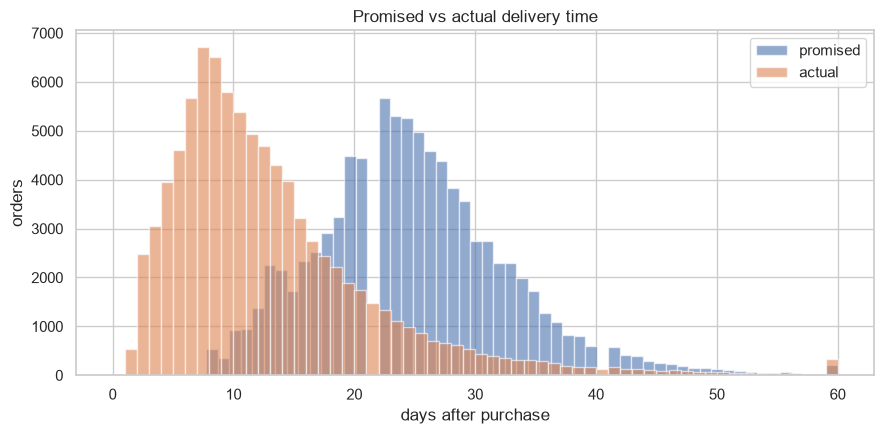

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df["promised_days"].clip(0, 60), bins=60, alpha=.6, label="promised")
ax.hist(df["actual_days"].clip(0, 60), bins=60, alpha=.6, label="actual")
ax.set(xlabel="days after purchase", ylabel="orders", title="Promised vs actual delivery time")
ax.legend(); fig.tight_layout(); fig.savefig(FIG + "promised_vs_actual.png", dpi=200)

## Phase 4 · EDA

                 mean   size
customer_state              
PA              0.118    899
RJ              0.125  11587
BA              0.128   3094
CE              0.144   1218
MA              0.180    684


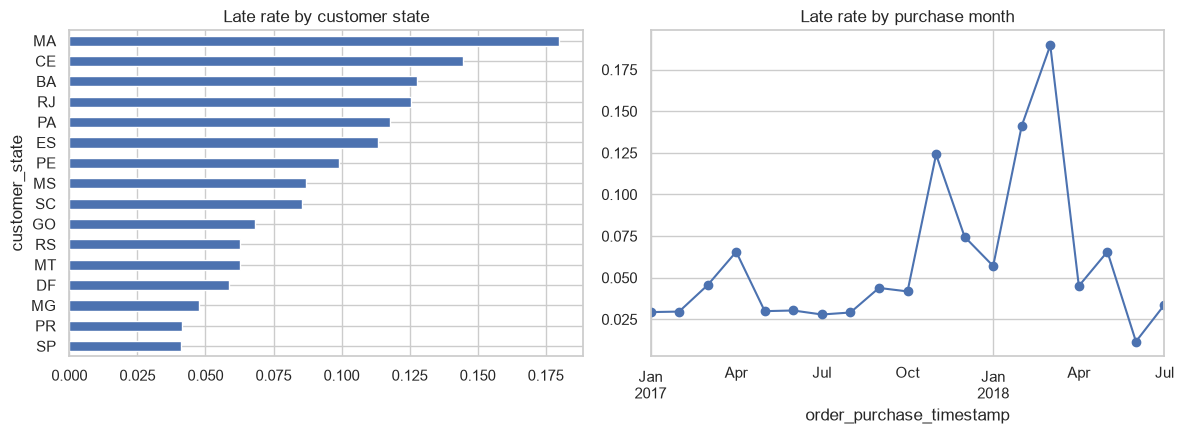

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
st = df.groupby("customer_state")["is_late"].agg(["mean", "size"]).query("size > 500").sort_values("mean")
st["mean"].plot.barh(ax=axes[0], title="Late rate by customer state")
m = df.groupby(df["order_purchase_timestamp"].dt.to_period("M"))["is_late"].mean()
m.plot(ax=axes[1], marker="o", title="Late rate by purchase month")
fig.tight_layout(); fig.savefig(FIG + "eda_state_month.png", dpi=200)
print(st.tail(5).round(3))

## Phase 5 · Feature engineering (checkout-time only)

In [11]:
g = t["geolocation"].groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()
for who, col in [("cust", "customer_zip_code_prefix"), ("sell", "seller_zip_code_prefix")]:
    df = df.merge(g.add_prefix(who + "_"), left_on=col, right_index=True, how="left")
la1, lo1, la2, lo2 = (np.radians(df[c]) for c in ["cust_geolocation_lat", "cust_geolocation_lng", "sell_geolocation_lat", "sell_geolocation_lng"])
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))

p = df["order_purchase_timestamp"]
df["hour"], df["weekday"], df["month"] = p.dt.hour, p.dt.weekday, p.dt.month
df["is_weekend"] = (df["weekday"] >= 5).astype(int)
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)
df["freight_ratio"] = df["freight"] / df["price"]

/var/folders/d7/d_t10ccj3050z2gr_mfh2w880000gn/T/ipykernel_81792/3369411255.py:8: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["hour"], df["weekday"], df["month"] = p.dt.hour, p.dt.weekday, p.dt.month


In [12]:
# Seller's past late rate, using ONLY deliveries that had already happened before this order was placed.
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)
ev = df[["seller_id", "order_delivered_customer_date", "is_late"]].sort_values("order_delivered_customer_date")
ev["seller_prev_deliveries"] = ev.groupby("seller_id").cumcount() + 1
ev["seller_prev_late"] = ev.groupby("seller_id")["is_late"].cumsum()
hist = pd.merge_asof(df[["order_purchase_timestamp", "seller_id"]].reset_index(),
                     ev.rename(columns={"order_delivered_customer_date": "t"})[["t", "seller_id", "seller_prev_deliveries", "seller_prev_late"]],
                     left_on="order_purchase_timestamp", right_on="t", by="seller_id",
                     allow_exact_matches=False).set_index("index")
df["seller_prev_deliveries"] = hist["seller_prev_deliveries"].fillna(0)
df["seller_late_rate"] = (hist["seller_prev_late"].fillna(0) + df["is_late"].mean() * 5) / (df["seller_prev_deliveries"] + 5)
print(df[["seller_prev_deliveries", "seller_late_rate"]].describe().round(3))

       seller_prev_deliveries  seller_late_rate
count               89852.000         89852.000
mean                  163.974             0.051
std                   271.608             0.041
min                     0.000             0.002
25%                    12.000             0.024
50%                    50.000             0.043
75%                   176.000             0.068
max                  1657.000             0.577


## Phase 5b · Leakage audit

In [13]:
LEAKY = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date",
         "actual_days", "order_status", "review_score"]
NUM = ["promised_days", "n_items", "price", "freight", "freight_ratio", "n_products", "n_sellers", "weight_g",
       "volume_cm3", "installments", "distance_km", "hour", "weekday", "month", "is_weekend", "same_state",
       "seller_prev_deliveries", "seller_late_rate"]
CAT = ["customer_state", "seller_state", "payment_type", "category"]
FEATURES = NUM + CAT
assert not set(FEATURES) & set(LEAKY), "leaky column in features"
print(f"{len(FEATURES)} features, none known only after checkout")
for c in CAT:
    df[c] = df[c].fillna("unknown").astype("category")

22 features, none known only after checkout


## Phase 6 · Chronological split (70 / 15 / 15)

In [14]:
fresh = df[df["order_purchase_timestamp"] >= "2018-07-01"]  # locked away until Experiment 2
base = df[df["order_purchase_timestamp"] < "2018-07-01"]
n = len(base); a, b = int(n * .70), int(n * .85)
train, val, test = base.iloc[:a], base.iloc[a:b], base.iloc[b:]
for name, d in [("train", train), ("val", val), ("test", test), ("fresh (locked)", fresh)]:
    print(f"{name:5s} {len(d):6,}  {d['order_purchase_timestamp'].min():%Y-%m-%d} to {d['order_purchase_timestamp'].max():%Y-%m-%d}  late {d['is_late'].mean():.1%}")
Xtr, ytr, Xva, yva, Xte, yte = train[FEATURES], train["is_late"], val[FEATURES], val["is_late"], test[FEATURES], test["is_late"]

train 58,587  2017-01-05 to 2018-03-07  late 7.2%
val   12,554  2018-03-07 to 2018-05-02  late 9.7%
test  12,555  2018-05-02 to 2018-06-30  late 4.0%
fresh (locked)  6,156  2018-07-01 to 2018-07-31  late 3.4%


## Phase 7 · Baseline: Logistic Regression

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

def report(name, y, s, top=0.10):
    k = int(len(s) * top); idx = np.argsort(-s)[:k]
    return {"model": name, "PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
            "Brier": brier_score_loss(y, s), "precision@top10%": y.iloc[idx].mean(), "recall@top10%": y.iloc[idx].sum() / y.sum()}

lr = make_pipeline(
    make_column_transformer((make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                            (OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT)),
    LogisticRegression(max_iter=2000, class_weight="balanced"))
lr.fit(Xtr, ytr)
rows = [{"model": "always 'on time'", "PR-AUC": yva.mean(), "ROC-AUC": .5, "Brier": brier_score_loss(yva, np.zeros(len(yva))),
         "precision@top10%": yva.mean(), "recall@top10%": .10},
        report("Logistic Regression", yva, lr.predict_proba(Xva)[:, 1])]
pd.DataFrame(rows).round(3)

,model,PR-AUC,ROC-AUC,Brier,precision@top10%,recall@top10%
0,always 'on time',0.097,0.500,0.097,0.097,0.100
1,Logistic Regression,0.220,0.722,0.274,0.269,0.276


## Phase 8 · LightGBM

In [16]:
import lightgbm as lgb
gbm = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
gbm.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)])
print("best iteration:", gbm.best_iteration_)
rows.append(report("LightGBM", yva, gbm.predict_proba(Xva)[:, 1]))
pd.DataFrame(rows).round(3)

/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best iteration: 78


,model,PR-AUC,ROC-AUC,Brier,precision@top10%,recall@top10%
0,always 'on time',0.097,0.500,0.097,0.097,0.100
1,Logistic Regression,0.220,0.722,0.274,0.269,0.276
2,LightGBM,0.299,0.784,0.078,0.344,0.354


## Phase 9 · Calibration (fit on validation, never on test)

In [17]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
iso = IsotonicRegression(out_of_bounds="clip").fit(gbm.predict_proba(Xva)[:, 1], yva)
calibrated = lambda X: iso.predict(gbm.predict_proba(X)[:, 1])

## Phase 10 · Final test (used once)

In [18]:
s_lr, s_raw, s_cal = lr.predict_proba(Xte)[:, 1], gbm.predict_proba(Xte)[:, 1], calibrated(Xte)
final = pd.DataFrame([report("Logistic Regression", yte, s_lr), report("LightGBM", yte, s_raw),
                      report("LightGBM + calibration", yte, s_cal)]).round(3)
print(f"test orders: {len(yte):,}   late: {yte.mean():.1%}")
final

test orders: 12,555   late: 4.0%


,model,PR-AUC,ROC-AUC,Brier,precision@top10%,recall@top10%
0,Logistic Regression,0.098,0.730,0.264,0.116,0.289
1,LightGBM,0.102,0.737,0.038,0.115,0.285
2,LightGBM + calibration,0.092,0.720,0.038,0.118,0.293


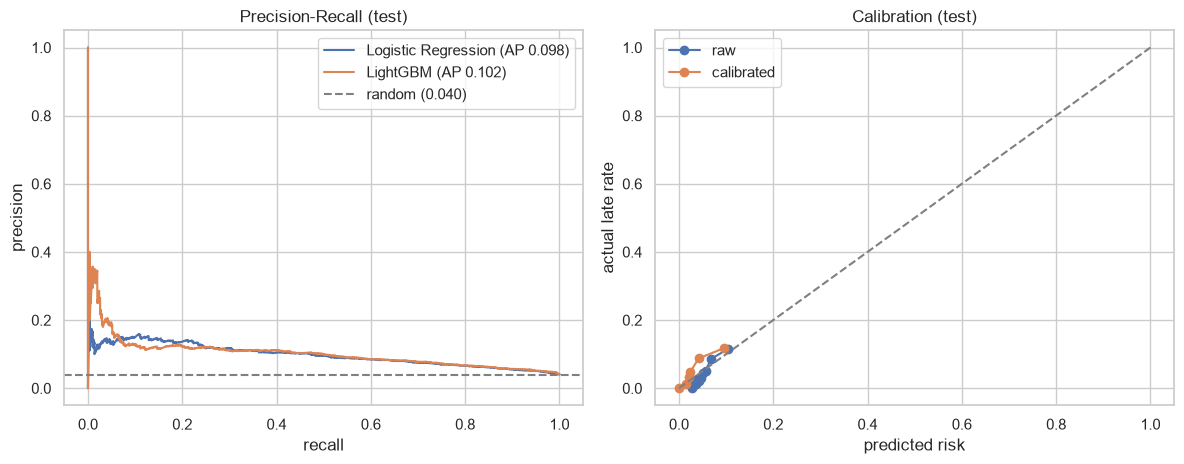

In [19]:
from sklearn.metrics import precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, s in [("Logistic Regression", s_lr), ("LightGBM", s_raw)]:
    pr, rc, _ = precision_recall_curve(yte, s); axes[0].plot(rc, pr, label=f"{name} (AP {average_precision_score(yte, s):.3f})")
axes[0].axhline(yte.mean(), ls="--", c="gray", label=f"random ({yte.mean():.3f})")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-Recall (test)"); axes[0].legend()
for name, s in [("raw", s_raw), ("calibrated", s_cal)]:
    f, m = calibration_curve(yte, s, n_bins=10, strategy="quantile"); axes[1].plot(m, f, marker="o", label=name)
axes[1].plot([0, 1], [0, 1], "--", c="gray"); axes[1].set(xlabel="predicted risk", ylabel="actual late rate", title="Calibration (test)"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG + "pr_and_calibration.png", dpi=200)

## Phase 11 · Risk bands for review priority

In [20]:
bands = pd.cut(s_cal, [0, .05, .15, .30, 1], labels=["Low", "Moderate", "High", "Very high"], include_lowest=True)
pd.DataFrame({"band": bands, "late": yte.values}).groupby("band", observed=True)["late"].agg(orders="size", actual_late_rate="mean").round(3)

,orders,actual_late_rate
band,,
Low,11528,0.033
Moderate,932,0.113
High,95,0.200


## Phase 12 · Explainability (SHAP)

/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


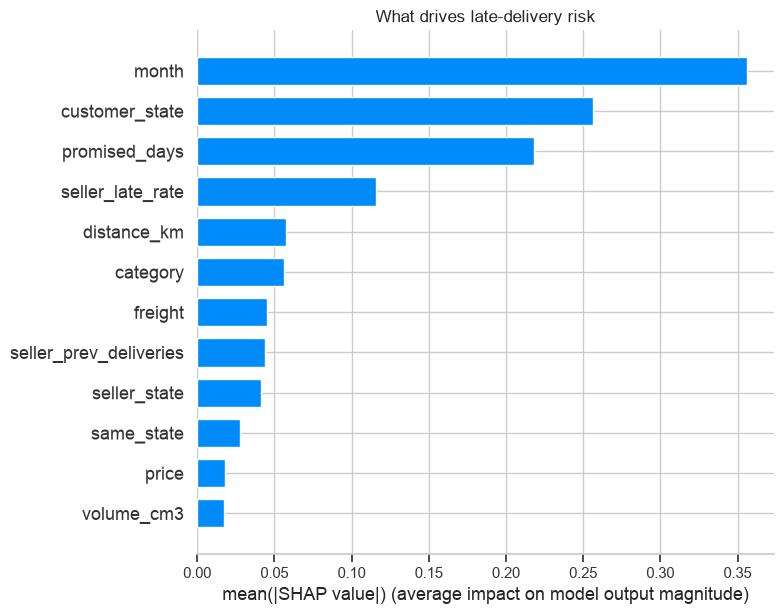

In [21]:
import shap
sample = Xte.sample(3000, random_state=SEED)
sv = shap.TreeExplainer(gbm).shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
plt.figure(); shap.summary_plot(sv, sample, plot_type="bar", max_display=12, show=False)
plt.title("What drives late-delivery risk"); plt.tight_layout(); plt.savefig(FIG + "shap_importance.png", dpi=200)

riskiest order in sample: 73295 calibrated risk 26%


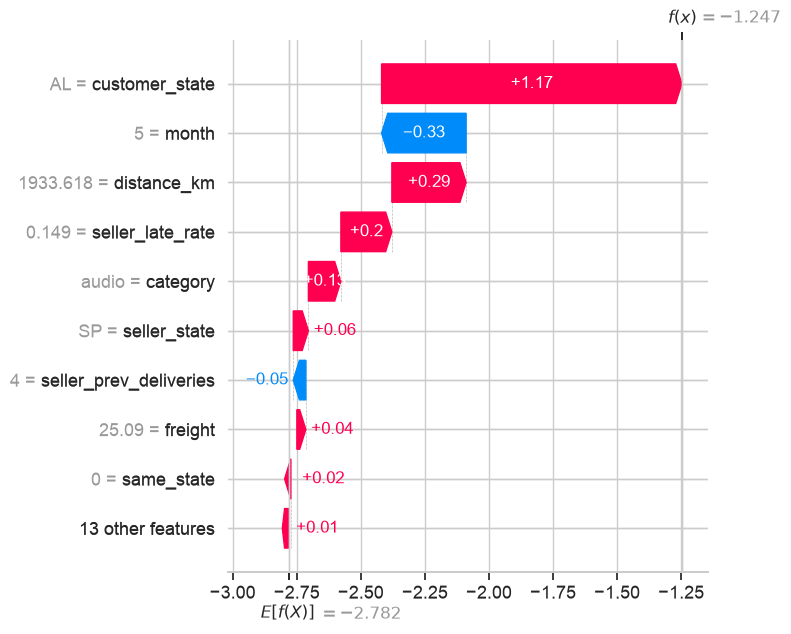

In [22]:
i = int(np.argmax(gbm.predict_proba(sample)[:, 1]))
exp = shap.TreeExplainer(gbm)(sample.iloc[[i]])
plt.figure(); shap.plots.waterfall(exp[0], max_display=10, show=False)
plt.tight_layout(); plt.savefig(FIG + "shap_riskiest_order.png", dpi=200)
print("riskiest order in sample:", sample.index[i], f"calibrated risk {iso.predict([gbm.predict_proba(sample.iloc[[i]])[0, 1]])[0]:.0%}")

## Phase 13 · Better promise: quantile regression on delivery days

In [23]:
NUM_P = [c for c in NUM if c != "promised_days"]
def fit_q(alpha):
    q = lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=600, learning_rate=0.05,
                          num_leaves=31, min_child_samples=50, random_state=SEED, verbose=-1)
    return q.fit(train[NUM_P + CAT], train["actual_days"])

# Pick the quantile on VALIDATION so our late rate matches Olist's own late rate there.
target_late = val["is_late"].mean()
best = None
for alpha in [0.85, 0.88, 0.90, 0.92, 0.94, 0.96]:
    q = fit_q(alpha); promise = np.ceil(q.predict(val[NUM_P + CAT]))
    late = (val["actual_days"] > promise).mean()
    print(f"alpha {alpha:.2f}  late {late:.2%}  mean promise {promise.mean():.1f} d")
    if best is None and late <= target_late: best = (alpha, q)
alpha, q = best if best else (alpha, q)
print(f"chosen alpha {alpha} (Olist late rate on validation {target_late:.2%})")

alpha 0.85  late 9.21%  mean promise 21.7 d


alpha 0.88  late 7.62%  mean promise 23.0 d


alpha 0.90  late 6.29%  mean promise 24.2 d


alpha 0.92  late 5.45%  mean promise 25.3 d


alpha 0.94  late 4.40%  mean promise 26.8 d


alpha 0.96  late 3.11%  mean promise 29.3 d
chosen alpha 0.85 (Olist late rate on validation 9.73%)


In [24]:
ml_promise = np.ceil(q.predict(test[NUM_P + CAT]))
cmp = pd.DataFrame({
    "promise": ["Olist today", "CommerceGuard"],
    "mean promised days": [test["promised_days"].mean(), ml_promise.mean()],
    "late rate": [test["is_late"].mean(), (test["actual_days"] > ml_promise).mean()]}).round(3)
print(f"promise shorter by {test['promised_days'].mean() - ml_promise.mean():.1f} days on average (test)")
cmp

promise shorter by 9.3 days on average (test)


,promise,mean promised days,late rate
0,Olist today,25.887,0.040
1,CommerceGuard,16.583,0.109


In [25]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist((test["promised_days"] - test["actual_days"]).clip(-20, 40), bins=60, alpha=.6, label="Olist promise - actual")
ax.hist((ml_promise - test["actual_days"]).clip(-20, 40), bins=60, alpha=.6, label="CommerceGuard promise - actual")
ax.axvline(0, c="k"); ax.set(xlabel="days of slack (negative = late)", ylabel="orders", title="How much padding each promise has (test)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG + "promise_slack.png", dpi=200)

## Experiment 1 failed. Why?
Validation (Mar-Apr 2018) was a late-heavy period, test (May-Jun 2018) was calm.
The model had no way to know "how is delivery going right now".

In [26]:
wk = base.groupby(base["order_purchase_timestamp"].dt.to_period("W"))["is_late"].mean()
fig, ax = plt.subplots(figsize=(10, 4)); wk.plot(ax=ax, marker=".")
for (lo, hi, lab) in [(val, None, "val"), (test, None, "test")]:
    ax.axvspan(lo["order_purchase_timestamp"].min().to_period("W"), lo["order_purchase_timestamp"].max().to_period("W"), alpha=.15)
ax.set(title="Weekly late rate: the world changed between validation and test", ylabel="late rate")
fig.tight_layout(); fig.savefig(FIG + "drift_weekly_late.png", dpi=200)

## Experiment 2 · Add 'how late is delivery right now' (known at checkout)

In [27]:
# Late rate of deliveries COMPLETED in the 30 days before each order was placed (overall and to the customer's state).
def recent_late(df, by=None, days=30):
    out = pd.Series(np.nan, index=df.index)
    groups = [(None, df)] if by is None else df.groupby(by, observed=True)
    for _, d in groups:
        e = d.sort_values("order_delivered_customer_date")
        t_ev = e["order_delivered_customer_date"].values; cum = np.concatenate([[0], e["is_late"].cumsum().values])
        tq = d["order_purchase_timestamp"].values
        hi = np.searchsorted(t_ev, tq, side="left"); lo = np.searchsorted(t_ev, tq - np.timedelta64(days, "D"), side="left")
        cnt = hi - lo; out.loc[d.index] = np.where(cnt >= 20, (cum[hi] - cum[lo]) / np.maximum(cnt, 1), np.nan)
    return out

df["recent_late_30d"] = recent_late(df)
df["recent_late_30d_state"] = recent_late(df, by="customer_state")
NUM2 = NUM + ["recent_late_30d", "recent_late_30d_state"]; FEATURES2 = NUM2 + CAT
assert not set(FEATURES2) & set(LEAKY)
base, fresh = df.loc[base.index], df.loc[fresh.index]
train, val, test = base.iloc[:a], base.iloc[a:b], base.iloc[b:]
print(df[["recent_late_30d", "recent_late_30d_state"]].describe().round(3))

       recent_late_30d  recent_late_30d_state
count        89727.000              87361.000
mean             0.066                  0.065
std              0.048                  0.074
min              0.000                  0.000
25%              0.035                  0.025
50%              0.047                  0.037
75%              0.089                  0.075
max              0.196                  0.642


In [28]:
gbm2 = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
gbm2.fit(train[FEATURES2], train["is_late"], eval_set=[(val[FEATURES2], val["is_late"])], eval_metric="average_precision",
         callbacks=[lgb.early_stopping(100, verbose=False)])
NUM2_P = [c for c in NUM2 if c != "promised_days"]
def fit_q2(alpha):
    return lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=600, learning_rate=0.05, num_leaves=31,
                             min_child_samples=50, random_state=SEED, verbose=-1).fit(train[NUM2_P + CAT], train["actual_days"])
# Same rule as before, chosen on validation only: the shortest promise whose late rate is not above Olist's.
best2 = None
for al in [0.85, 0.88, 0.90, 0.92, 0.94, 0.96]:
    qq = fit_q2(al); pr = np.ceil(qq.predict(val[NUM2_P + CAT])); late = (val["actual_days"] > pr).mean()
    print(f"alpha {al:.2f}  val late {late:.2%}  mean promise {pr.mean():.1f} d")
    if best2 is None and late <= val["is_late"].mean(): best2 = (al, qq)
alpha2, q2 = best2
print("chosen alpha", alpha2)

/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


alpha 0.85  val late 10.92%  mean promise 20.3 d


alpha 0.88  val late 9.40%  mean promise 21.6 d


alpha 0.90  val late 7.98%  mean promise 22.4 d


alpha 0.92  val late 6.03%  mean promise 24.2 d


alpha 0.94  val late 4.77%  mean promise 25.8 d


alpha 0.96  val late 3.31%  mean promise 28.5 d
chosen alpha 0.88


## Final check on July 2018: never seen by any model or choice

In [29]:
yf = fresh["is_late"]
ffinal = pd.DataFrame([report("Exp 1 LightGBM", yf, gbm.predict_proba(fresh[FEATURES])[:, 1]),
                       report("Exp 2 LightGBM + recent-late", yf, gbm2.predict_proba(fresh[FEATURES2])[:, 1])]).round(3)
p1, p2 = np.ceil(q.predict(fresh[NUM_P + CAT])), np.ceil(q2.predict(fresh[NUM2_P + CAT]))
fprom = pd.DataFrame({"promise": ["Olist today", "Exp 1 quantile", "Exp 2 quantile + recent-late"],
                      "mean promised days": [fresh["promised_days"].mean(), p1.mean(), p2.mean()],
                      "late rate": [yf.mean(), (fresh["actual_days"] > p1).mean(), (fresh["actual_days"] > p2).mean()]}).round(3)
print(f"fresh orders: {len(fresh):,}   late: {yf.mean():.1%}   random PR-AUC = {yf.mean():.3f}")
display(ffinal); fprom

fresh orders: 6,156   late: 3.4%   random PR-AUC = 0.034


,model,PR-AUC,ROC-AUC,Brier,precision@top10%,recall@top10%
0,Exp 1 LightGBM,0.063,0.661,0.033,0.076,0.226
1,Exp 2 LightGBM + recent-late,0.066,0.633,0.033,0.065,0.192


,promise,mean promised days,late rate
0,Olist today,20.329,0.034
1,Exp 1 quantile,16.509,0.062
2,Exp 2 quantile + recent-late,17.037,0.058


In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(fprom["promise"], fprom["mean promised days"], color=["#888", "#e76f51", "#2a9d8f"])
for i, r in fprom.iterrows():
    ax.text(i, r["mean promised days"] + .3, f"{r['mean promised days']:.1f} d\nlate {r['late rate']:.1%}", ha="center")
ax.set(ylabel="mean promised days", title="July 2018 (untouched): promise length vs late rate")
fig.tight_layout(); fig.savefig(FIG + "promise_fresh_month.png", dpi=200)

## Summary
- One row per order, checkout-time features only, chronological split, test used once.
- Limits: Brazil data (not COD / Bangladesh); "late" is not "failed"; customer history is almost empty
  because most people order once. Next episode: COD failure with a real merchant's data.